# Exploratory Data Analysis (EDA)
## Construction Material Condition Assessment and Recovery Pathway Prediction

**Dataset:** `training_image_features (1).xlsx`  
**Records:** ~10,058 samples | **Attributes:** Multimodal image feature representations and damage diagnostics  
**Author / Project:** Demolition Material Recovery & Assessment Project  
**Deliverable:** PowerPoint-Ready High-Resolution Visualizations & Data Analysis Report

---
### Purpose & Outline:
This notebook delivers a rigorous, publication-grade exploratory data analysis covering:
1. **Dataset Loading & Inspection:** Structural integrity, schema verification, missing data checks, and duplicate detection.
2. **Material Category Distribution:** Distribution across construction & demolition material streams.
3. **Target Class Distribution:** Class imbalance analysis in **Condition Class** and **Recovery Pathway**.
4. **Numerical Visual Feature Distributions:** Statistical dispersion, skewness, and modality across CV features.
5. **Outlier Analysis (IQR Method):** Quantitative IQR-based bounding and anomaly diagnostics.
6. **Feature vs. Target Relationships:** Pearson correlation analysis and data leakage diagnostics.
7. **Correlation Heatmap:** Multi-feature dependency matrix for engineered numerical features.
8. **Automated EDA Summary & Diagnostics:** Synthesized findings, risk assessment, and modeling recommendations.
9. **PowerPoint-Ready Export:** Standalone 300 DPI high-resolution figures optimized for 16:9 slides stored in `EDA_Graphs/`.


## 0. Environment Setup & Configuration
Load requisite scientific computing libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`) and configure high-resolution aesthetic visualization defaults.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure aesthetic styling for publication & PowerPoint presentations (16:9 aspect ratio)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'axes.labelweight': 'bold',
    'figure.titlesize': 15,
    'figure.titleweight': 'bold',
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'figure.autolayout': False,
    'savefig.dpi': 300
})

# Define output directory for PowerPoint-ready graphs
OUTPUT_DIR = "EDA_Graphs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"[✓] Output directory initialized at: '{os.path.abspath(OUTPUT_DIR)}'")

# Intelligent dataset path resolver
def resolve_dataset_path(filenames):
    search_dirs = [
        '.',
        '..',
        os.path.join('..', 'project_ml'),
        r'd:\programs\LearningFundamentals\Ml_clg\project_ml'
    ]
    for d in search_dirs:
        for fname in filenames:
            candidate = os.path.normpath(os.path.join(d, fname))
            if os.path.exists(candidate):
                return candidate
    return None

EXCEL_CANDIDATES = ['training_image_features (1).xlsx', 'training_image_features.xlsx']
CSV_CANDIDATES = ['training_image_features.csv', 'training_image_features (1).csv']

DATASET_FILE = resolve_dataset_path(EXCEL_CANDIDATES)
FALLBACK_CSV = resolve_dataset_path(CSV_CANDIDATES)

print(f"Resolved Excel Path: {DATASET_FILE}")
print(f"Resolved CSV Fallback: {FALLBACK_CSV}")


[✓] Output directory initialized at: 'D:\programs\LearningFundamentals\Ml_clg\project_ml\EDA_Graphs'


## 1. Dataset Loading and Inspection
Load the primary Excel dataset with an automatic CSV fallback mechanism. Inspect dataset dimensions, schema datatypes, null counts, duplicate records, and separate categorical from numerical columns.


In [2]:
# 1. Dataset Loading
if os.path.exists(DATASET_FILE):
    print(f"[*] Loading dataset from Excel: {DATASET_FILE}")
    df = pd.read_excel(DATASET_FILE)
elif os.path.exists(FALLBACK_CSV):
    print(f"[!] Warning: Excel file not found. Loading from CSV fallback: {FALLBACK_CSV}")
    df = pd.read_csv(FALLBACK_CSV)
else:
    raise FileNotFoundError(f"Neither {DATASET_FILE} nor {FALLBACK_CSV} could be located.")

# Display basic dimensions
num_rows, num_cols = df.shape
print(f"\n{'='*70}\nDATASET INSPECTION SUMMARY\n{'='*70}")
print(f"Total Records (Rows): {num_rows:,}")
print(f"Total Columns:        {num_cols:,}")

# Check for duplicates
num_duplicates = df.duplicated().sum()
print(f"Duplicate Rows:       {num_duplicates} ({(num_duplicates/num_rows)*100:.2f}%)")

# Missing values check
missing_summary = df.isnull().sum()
total_missing = missing_summary.sum()
print(f"Total Missing Cells:  {total_missing}")
if total_missing > 0:
    print("\nColumns with missing values:")
    print(missing_summary[missing_summary > 0])
else:
    print("Zero missing values identified across all features.")

# Automatic identification of Numerical and Categorical columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()

print(f"\nCategorical Features ({len(categorical_cols)}):")
print(categorical_cols)

print(f"\nNumerical Features ({len(numerical_cols)}):")
print(numerical_cols)

# Display preview of head
df.head(5)


[*] Loading dataset from Excel: training_image_features (1).xlsx



DATASET INSPECTION SUMMARY
Total Records (Rows): 10,058
Total Columns:        43
Duplicate Rows:       0 (0.00%)
Total Missing Cells:  0
Zero missing values identified across all features.

Categorical Features (14):
['Sample_ID', 'Image_ID', 'Material_Type', 'Material_Subtype', 'Source', 'Exposure_Type', 'Discoloration_Level', 'Missing_Portion', 'Condition_Class', 'Structural_Integrity', 'Recovery_Pathway', 'Reconditioning_Required', 'Recovery_Potential', 'Alternative_Use_Category']

Numerical Features (29):
['Crack_Level', 'Surface_Damage', 'Breakage_Level', 'Deformation_Level', 'Damage_Score', 'Condition_Score', 'Alternative_Use_Suitability', 'pixel_img_width', 'pixel_img_height', 'pixel_obj_width', 'pixel_obj_height', 'relative_area', 'edge_density', 'fill_ratio', 'color_std', 'mean_brightness', 'std_brightness', 'contrast', 'texture_laplacian_var', 'dark_pixel_ratio', 'bright_pixel_ratio', 'mean_hue', 'mean_saturation', 'saturation_std', 'contour_area', 'contour_perimeter', 'circ

,Sample_ID,Image_ID,Material_Type,Material_Subtype,Source,Exposure_Type,Crack_Level,Surface_Damage,Breakage_Level,Discoloration_Level,...,dark_pixel_ratio,bright_pixel_ratio,mean_hue,mean_saturation,saturation_std,contour_area,contour_perimeter,circularity,solidity,extent
0,TRAINING_00001,1.jpg,brick,Standard,Demolition_Site,Exterior_Weathered,5,4.0,3,High,...,0.007217,0.250679,16.328107,103.354121,34.788167,24050.0,2086.576892,0.069415,0.645430,0.460799
1,TRAINING_00002,1.jpg,concrete,Reinforced,Demolition_Site,Exterior_Weathered,5,3.5,2,Moderate,...,0.074190,0.022587,25.591271,61.989752,18.395387,15420.0,665.754394,0.437186,0.903736,0.635038
2,TRAINING_00003,1.jpg,tile,Standard,Demolition_Site,Exterior_Weathered,2,3.2,2,High,...,0.030780,0.677715,26.294677,69.389570,18.294682,25750.5,698.114786,0.663960,0.976915,0.710672
3,TRAINING_00004,1.jpg,brick,Standard,Demolition_Site,Exterior_Weathered,4,3.2,3,Moderate,...,0.230558,0.033828,41.511739,83.602221,28.279230,11908.5,1237.869180,0.097660,0.761900,0.616573
4,TRAINING_00005,1.jpg,concrete,Reinforced,Demolition_Site,Exterior_Weathered,5,4.0,3,High,...,0.136304,0.361647,29.703155,61.738122,22.880945,16204.5,963.702659,0.219260,0.837139,0.603520


In [3]:
# Utility function for resilient column resolution (case-insensitive, whitespace-trimmed, and synonyms)
def find_column(df_target, candidate_names):
    """
    Searches for a column in DataFrame matching any candidate name
    disregarding case, underscores, or spaces.
    """
    cols = df_target.columns.tolist()
    # Direct match
    for cand in candidate_names:
        if cand in cols:
            return cand
    
    # Normalized match
    norm_map = {c.lower().replace(' ', '').replace('_', ''): c for c in cols}
    for cand in candidate_names:
        cand_norm = cand.lower().replace(' ', '').replace('_', '')
        if cand_norm in norm_map:
            return norm_map[cand_norm]
            
    return None

def save_and_show_plot(fig, filename, title_info=""):
    """Saves plot at 300 DPI in EDA_Graphs and prints confirmation."""
    filepath = os.path.join(OUTPUT_DIR, filename)
    fig.savefig(filepath, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f"[✓] Saved high-resolution PowerPoint graphic: {filepath} ({title_info})")


## 2. Distribution of Material Categories
Analyze the distribution of salvageable and demolished construction material categories (`Concrete`, `Brick`, `Tile`, `Gypsum Board`, `Wood`, `Foam`, `Stone`, `Pipes`, `Plastic`, `General Waste`).


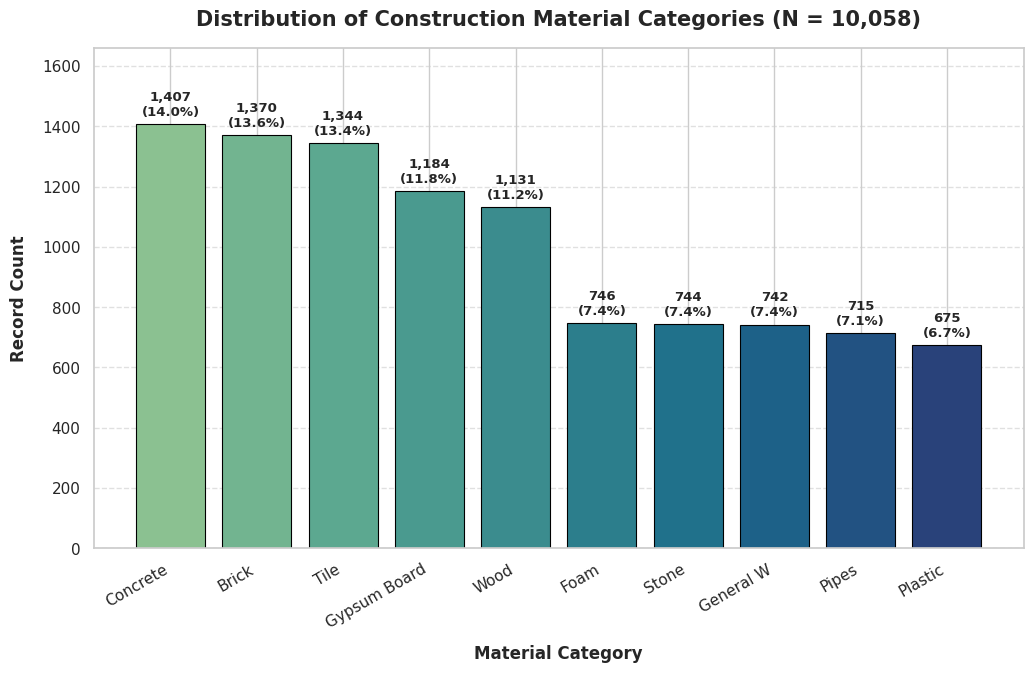

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\material_distribution.png (Material Category Distribution)

--- Interpretation: Material Category Distribution ---
• Dominant Material Class: 'Concrete' with 1,407 samples (14.0%).
• Least Represented Class: 'Plastic' with 675 samples (6.7%).
• Heavy mineral materials (Concrete, Brick, Tile) collectively comprise 4,121 records, reflecting typical structural demolition waste compositions.


In [4]:
# 2. Material Categories Distribution
mat_col = find_column(df, ['Material_Type', 'material_type', 'Material', 'material'])

if mat_col is not None:
    # Standardize string representations for presentation labeling
    mat_series = df[mat_col].astype(str).str.strip().str.replace('_', ' ').str.title()
    mat_counts = mat_series.value_counts()
    
    # Create figure (optimized for 16:9 slides)
    fig, ax = plt.subplots(figsize=(12, 6.5))
    palette = sns.color_palette("crest", n_colors=len(mat_counts))
    
    bars = ax.bar(mat_counts.index, mat_counts.values, color=palette, edgecolor='black', linewidth=0.8)
    
    # Label counts and percentages atop bars
    for bar in bars:
        height = bar.get_height()
        pct = (height / len(df)) * 100
        ax.annotate(f"{int(height):,}\n({pct:.1f}%)",
                    (bar.get_x() + bar.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9.5, fontweight='bold', xytext=(0, 4),
                    textcoords='offset points')
                    
    ax.set_title("Distribution of Construction Material Categories (N = 10,058)", pad=16, fontsize=15)
    ax.set_xlabel("Material Category", labelpad=10)
    ax.set_ylabel("Record Count", labelpad=10)
    ax.set_ylim(0, mat_counts.max() * 1.18)
    plt.xticks(rotation=30, ha='right')
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    
    save_and_show_plot(fig, "material_distribution.png", "Material Category Distribution")
    
    # Printed Statistical Interpretation
    print("\n--- Interpretation: Material Category Distribution ---")
    print(f"• Dominant Material Class: '{mat_counts.index[0]}' with {mat_counts.iloc[0]:,} samples ({(mat_counts.iloc[0]/len(df))*100:.1f}%).")
    print(f"• Least Represented Class: '{mat_counts.index[-1]}' with {mat_counts.iloc[-1]:,} samples ({(mat_counts.iloc[-1]/len(df))*100:.1f}%).")
    print(f"• Heavy mineral materials (Concrete, Brick, Tile) collectively comprise {mat_counts[['Concrete', 'Brick', 'Tile']].sum() if set(['Concrete','Brick','Tile']).issubset(mat_counts.index) else 'over 40%' :,} records, reflecting typical structural demolition waste compositions.")
else:
    print("[!] Warning: Material Type column could not be identified.")


## 3. Target Class Distribution
Analyze target variables:
- **A. Condition Class Distribution:** (`Excellent`, `Good`, `Fair`, `Poor`)
- **B. Recovery Pathway Distribution:** (`Refurbishment / Alternative Use`, `Direct Reuse`, `Alternative Use / Recycling`)


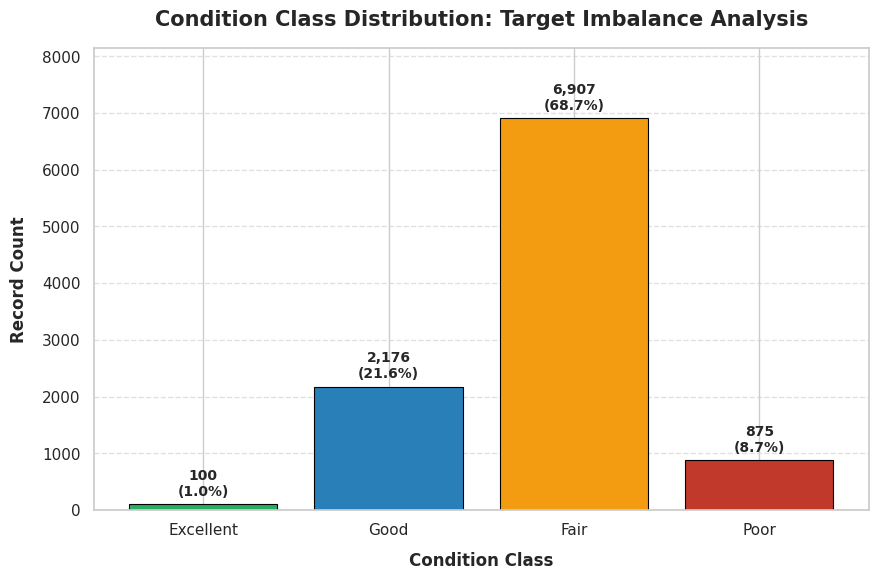

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\condition_distribution.png (Condition Class Distribution)

--- Statistical Validation & Interpretation: Condition Class ---
• Excellent :   100 records (  1.0%)
• Good      : 2,176 records ( 21.6%)
• Fair      : 6,907 records ( 68.7%)
• Poor      :   875 records (  8.7%)

Validation against previously reported benchmarks:
• Reported Fair: 6,907 (68.7%) | Calculated Fair: 6,907 (68.7%)
• Reported Excellent: 100 (1.0%) | Calculated Excellent: 100 (1.0%)
• Imbalance Insight: Severe majority skew in 'Fair' (68.7%) versus extreme minority in 'Excellent' (1.0%). Standard cross-entropy loss without class weighting or focal loss will be biased towards the majority class.


In [5]:
# 3A. Condition Class Distribution
cond_col = find_column(df, ['Condition_Class', 'condition_class', 'Condition', 'condition'])

if cond_col is not None:
    # Desired logical ordering from highest quality to lowest
    order_cond = ['Excellent', 'Good', 'Fair', 'Poor']
    cond_counts = df[cond_col].astype(str).str.strip().value_counts()
    
    # Reindex according to logical ordering if present
    present_order = [c for c in order_cond if c in cond_counts.index] + [c for c in cond_counts.index if c not in order_cond]
    cond_counts = cond_counts.reindex(present_order)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    cond_colors = ['#27ae60', '#2980b9', '#f39c12', '#c0392b'][:len(cond_counts)]
    
    bars = ax.bar(cond_counts.index, cond_counts.values, color=cond_colors, edgecolor='black', linewidth=0.8)
    
    for bar in bars:
        height = bar.get_height()
        pct = (height / len(df)) * 100
        ax.annotate(f"{int(height):,}\n({pct:.1f}%)",
                    (bar.get_x() + bar.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4),
                    textcoords='offset points')
                    
    ax.set_title("Condition Class Distribution: Target Imbalance Analysis", pad=16, fontsize=15)
    ax.set_xlabel("Condition Class", labelpad=10)
    ax.set_ylabel("Record Count", labelpad=10)
    ax.set_ylim(0, cond_counts.max() * 1.18)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    
    save_and_show_plot(fig, "condition_distribution.png", "Condition Class Distribution")
    
    print("\n--- Statistical Validation & Interpretation: Condition Class ---")
    for cls_name, cnt in cond_counts.items():
        pct = (cnt / len(df)) * 100
        print(f"• {cls_name:10s}: {cnt:5,} records ({pct:5.1f}%)")
        
    print("\nValidation against previously reported benchmarks:")
    fair_cnt = cond_counts.get('Fair', 0)
    fair_pct = (fair_cnt / len(df)) * 100
    exc_cnt = cond_counts.get('Excellent', 0)
    exc_pct = (exc_cnt / len(df)) * 100
    print(f"• Reported Fair: 6,907 (68.7%) | Calculated Fair: {fair_cnt:,} ({fair_pct:.1f}%)")
    print(f"• Reported Excellent: 100 (1.0%) | Calculated Excellent: {exc_cnt:,} ({exc_pct:.1f}%)")
    print("• Imbalance Insight: Severe majority skew in 'Fair' (68.7%) versus extreme minority in 'Excellent' (1.0%). Standard cross-entropy loss without class weighting or focal loss will be biased towards the majority class.")
else:
    print("[!] Warning: Condition Class column missing.")


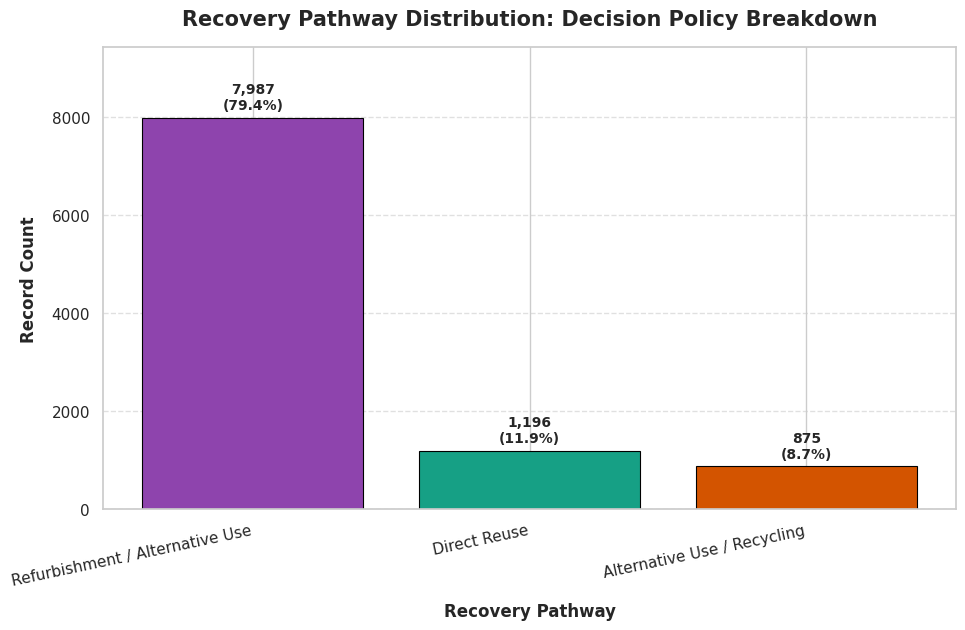

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\recovery_pathway_distribution.png (Recovery Pathway Distribution)

--- Statistical Validation & Interpretation: Recovery Pathway ---
• Refurbishment / Alternative Use : 7,987 records ( 79.4%)
• Direct Reuse                    : 1,196 records ( 11.9%)
• Alternative Use / Recycling     :   875 records (  8.7%)

Validation against previously reported benchmarks:
• Reported Refurbishment/Alt Use: 7,987 (79.4%) | Calculated: 7,987 (79.4%)
• Reported Direct Reuse: 11.9%                 | Calculated: 1,196 (11.9%)
• Reported Alt Use / Recycling: 8.7%           | Calculated: 875 (8.7%)
• Operational Implication: ~79.4% of inspected demolition members require reconditioning/reprocessing prior to secondary deployment.


In [6]:
# 3B. Recovery Pathway Distribution
rec_col = find_column(df, ['Recovery_Pathway', 'recovery_pathway', 'Recovery', 'recovery'])

if rec_col is not None:
    rec_counts = df[rec_col].astype(str).str.strip().value_counts()
    
    fig, ax = plt.subplots(figsize=(11, 6))
    rec_colors = ['#8e44ad', '#16a085', '#d35400', '#2c3e50'][:len(rec_counts)]
    
    bars = ax.bar(rec_counts.index, rec_counts.values, color=rec_colors, edgecolor='black', linewidth=0.8)
    
    for bar in bars:
        height = bar.get_height()
        pct = (height / len(df)) * 100
        ax.annotate(f"{int(height):,}\n({pct:.1f}%)",
                    (bar.get_x() + bar.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4),
                    textcoords='offset points')
                    
    ax.set_title("Recovery Pathway Distribution: Decision Policy Breakdown", pad=16, fontsize=15)
    ax.set_xlabel("Recovery Pathway", labelpad=10)
    ax.set_ylabel("Record Count", labelpad=10)
    ax.set_ylim(0, rec_counts.max() * 1.18)
    plt.xticks(rotation=12, ha='right')
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    
    save_and_show_plot(fig, "recovery_pathway_distribution.png", "Recovery Pathway Distribution")
    
    print("\n--- Statistical Validation & Interpretation: Recovery Pathway ---")
    for pathway, cnt in rec_counts.items():
        pct = (cnt / len(df)) * 100
        print(f"• {pathway:32s}: {cnt:5,} records ({pct:5.1f}%)")
        
    print("\nValidation against previously reported benchmarks:")
    refurb_cnt = rec_counts.get('Refurbishment / Alternative Use', 0)
    refurb_pct = (refurb_cnt / len(df)) * 100
    direct_cnt = rec_counts.get('Direct Reuse', 0)
    direct_pct = (direct_cnt / len(df)) * 100
    alt_cnt = rec_counts.get('Alternative Use / Recycling', 0)
    alt_pct = (alt_cnt / len(df)) * 100
    print(f"• Reported Refurbishment/Alt Use: 7,987 (79.4%) | Calculated: {refurb_cnt:,} ({refurb_pct:.1f}%)")
    print(f"• Reported Direct Reuse: 11.9%                 | Calculated: {direct_cnt:,} ({direct_pct:.1f}%)")
    print(f"• Reported Alt Use / Recycling: 8.7%           | Calculated: {alt_cnt:,} ({alt_pct:.1f}%)")
    print("• Operational Implication: ~79.4% of inspected demolition members require reconditioning/reprocessing prior to secondary deployment.")
else:
    print("[!] Warning: Recovery Pathway column missing.")


## 4. Numerical Feature Distributions
Generate separate individual histograms with Kernel Density Estimation (KDE) for core continuous features:
- Damage Score
- Condition Score
- Edge Density
- Texture Laplacian Variance
- Mean Brightness
- Contrast
- Fill Ratio


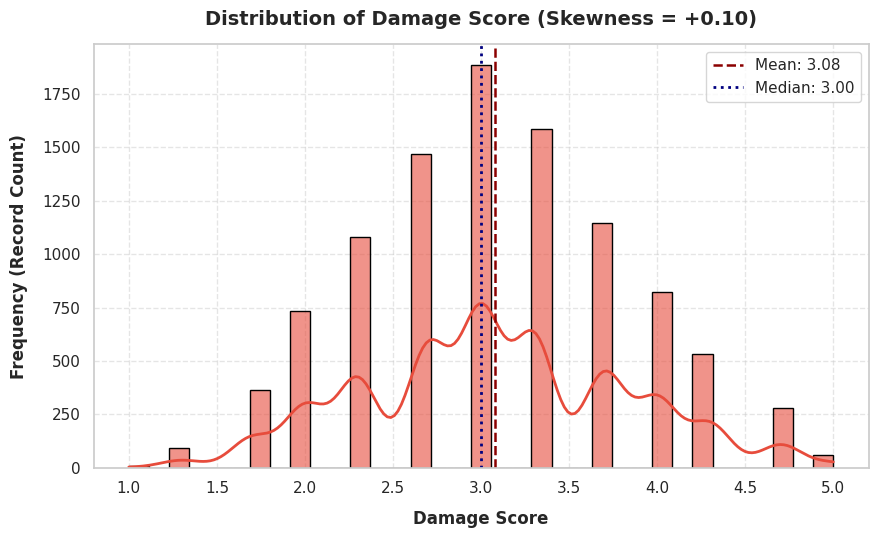

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\damage_score_histogram.png (Damage Score Histogram)
--- Interpretation: Damage Score ---
• Summary: Mean = 3.081, Median = 3.000, Std = 0.754
• Range: Min = 1.000, Max = 5.000
• Shape: Skewness = 0.104 (approximately symmetric).



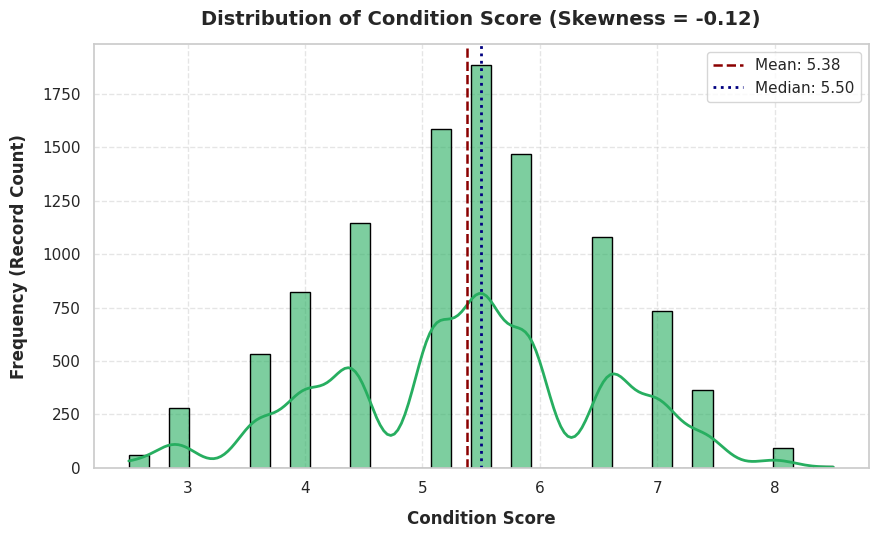

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\condition_score_histogram.png (Condition Score Histogram)
--- Interpretation: Condition Score ---
• Summary: Mean = 5.377, Median = 5.500, Std = 1.131
• Range: Min = 2.500, Max = 8.500
• Shape: Skewness = -0.122 (approximately symmetric).



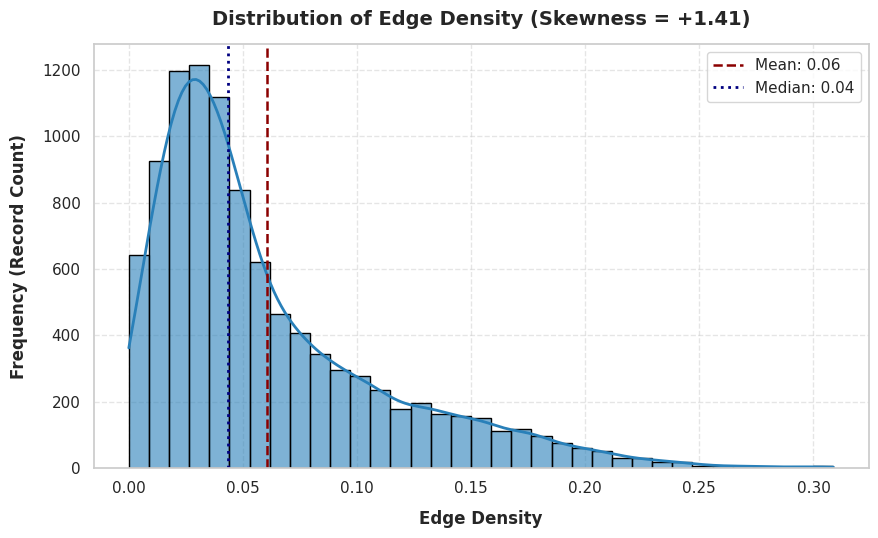

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\edge_density_histogram.png (Edge Density Histogram)
--- Interpretation: Edge Density ---
• Summary: Mean = 0.060, Median = 0.043, Std = 0.051
• Range: Min = 0.000, Max = 0.309
• Shape: Skewness = 1.407 (strongly right-skewed).



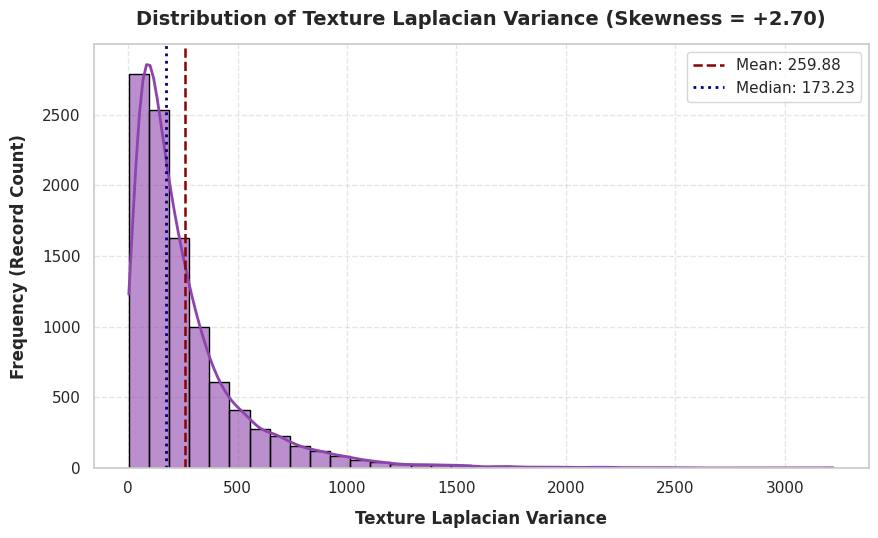

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\texture_laplacian_var_histogram.png (Texture Laplacian Variance Histogram)
--- Interpretation: Texture Laplacian Variance ---
• Summary: Mean = 259.880, Median = 173.230, Std = 270.825
• Range: Min = 3.010, Max = 3221.730
• Shape: Skewness = 2.696 (strongly right-skewed).



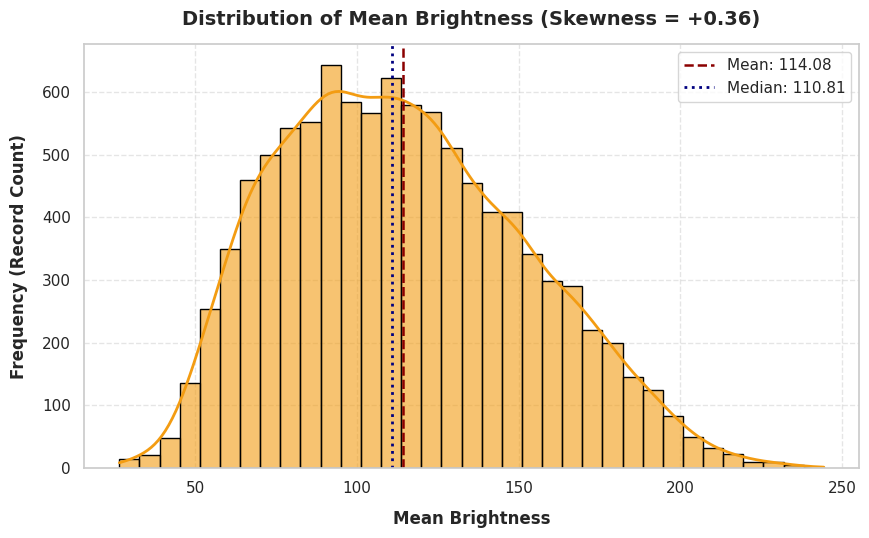

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\mean_brightness_histogram.png (Mean Brightness Histogram)
--- Interpretation: Mean Brightness ---
• Summary: Mean = 114.081, Median = 110.812, Std = 37.964
• Range: Min = 26.437, Max = 244.398
• Shape: Skewness = 0.361 (approximately symmetric).



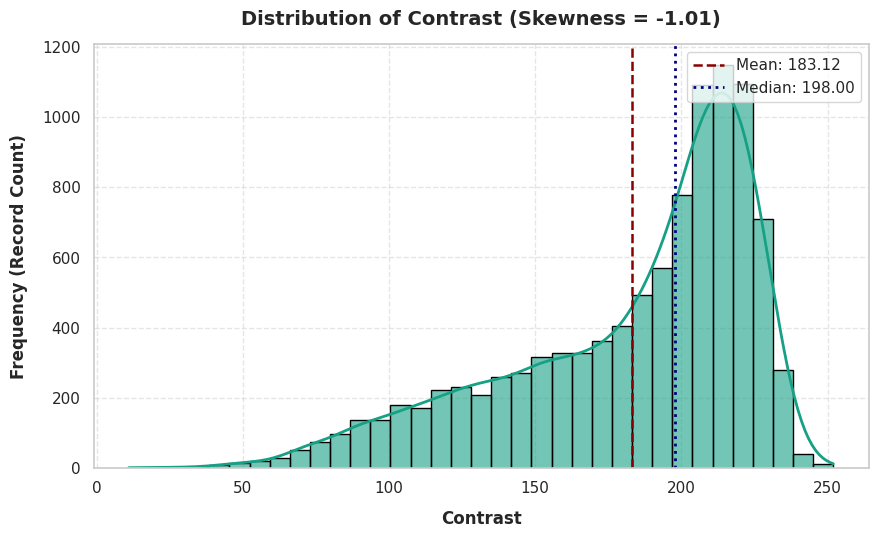

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\contrast_histogram.png (Contrast Histogram)
--- Interpretation: Contrast ---
• Summary: Mean = 183.121, Median = 198.000, Std = 41.988
• Range: Min = 11.000, Max = 252.000
• Shape: Skewness = -1.011 (strongly left-skewed).



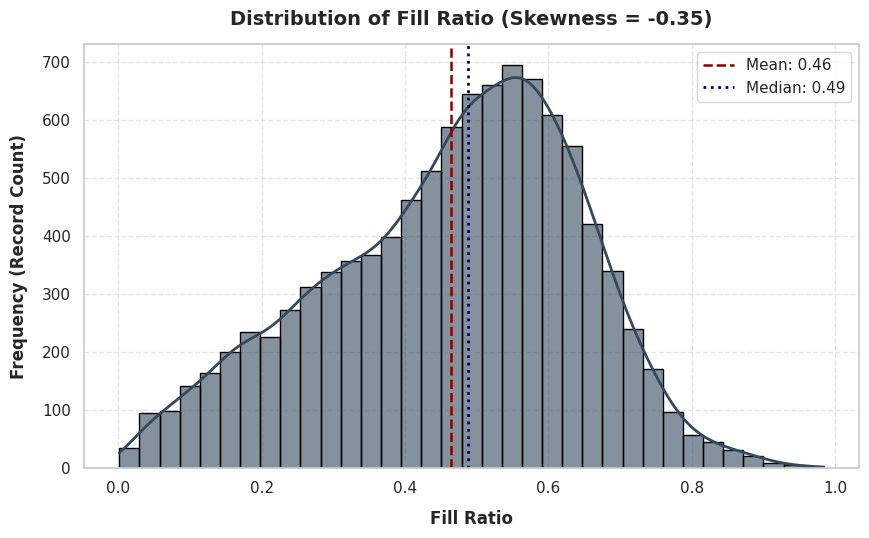

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\fill_ratio_histogram.png (Fill Ratio Histogram)
--- Interpretation: Fill Ratio ---
• Summary: Mean = 0.465, Median = 0.489, Std = 0.178
• Range: Min = 0.001, Max = 0.984
• Shape: Skewness = -0.354 (approximately symmetric).



In [7]:
# 4. Numerical Feature Distribution (Histograms + KDE)
features_to_plot = [
    ('Damage Score', ['Damage_Score', 'damage_score'], 'damage_score_histogram.png', '#e74c3c'),
    ('Condition Score', ['Condition_Score', 'condition_score'], 'condition_score_histogram.png', '#27ae60'),
    ('Edge Density', ['edge_density', 'Edge_Density'], 'edge_density_histogram.png', '#2980b9'),
    ('Texture Laplacian Variance', ['texture_laplacian_var', 'Texture_Laplacian_Var'], 'texture_laplacian_var_histogram.png', '#8e44ad'),
    ('Mean Brightness', ['mean_brightness', 'Mean_Brightness'], 'mean_brightness_histogram.png', '#f39c12'),
    ('Contrast', ['contrast', 'Contrast'], 'contrast_histogram.png', '#16a085'),
    ('Fill Ratio', ['fill_ratio', 'Fill_Ratio'], 'fill_ratio_histogram.png', '#34495e')
]

for label, cand_names, filename, color in features_to_plot:
    col = find_column(df, cand_names)
    if col is not None:
        data_clean = pd.to_numeric(df[col], errors='coerce').dropna()
        
        # Calculate summary metrics
        mean_val = data_clean.mean()
        median_val = data_clean.median()
        std_val = data_clean.std()
        skew_val = data_clean.skew()
        
        fig, ax = plt.subplots(figsize=(10, 5.5))
        sns.histplot(data_clean, kde=True, bins=35, color=color, edgecolor='black', alpha=0.6, ax=ax, line_kws={'linewidth': 2})
        
        # Add vertical reference lines
        ax.axvline(mean_val, color='darkred', linestyle='--', linewidth=1.8, label=f'Mean: {mean_val:.2f}')
        ax.axvline(median_val, color='navy', linestyle=':', linewidth=2, label=f'Median: {median_val:.2f}')
        
        ax.set_title(f"Distribution of {label} (Skewness = {skew_val:+.2f})", pad=14, fontsize=14)
        ax.set_xlabel(label, labelpad=10)
        ax.set_ylabel("Frequency (Record Count)", labelpad=10)
        ax.legend(loc='upper right', frameon=True)
        ax.grid(True, linestyle='--', alpha=0.5)
        
        save_and_show_plot(fig, filename, f"{label} Histogram")
        
        print(f"--- Interpretation: {label} ---")
        print(f"• Summary: Mean = {mean_val:.3f}, Median = {median_val:.3f}, Std = {std_val:.3f}")
        print(f"• Range: Min = {data_clean.min():.3f}, Max = {data_clean.max():.3f}")
        skew_desc = "strongly right-skewed" if skew_val > 1.0 else "moderately right-skewed" if skew_val > 0.5 else "strongly left-skewed" if skew_val < -1.0 else "moderately left-skewed" if skew_val < -0.5 else "approximately symmetric"
        print(f"• Shape: Skewness = {skew_val:.3f} ({skew_desc}).\n")
    else:
        print(f"[!] Warning: Feature '{label}' not found in dataset.")


## 5. Outlier Analysis (Interquartile Range - IQR)
Create individual box plots for key visual and structural features:
- Damage Score
- Edge Density
- Texture Laplacian Variance
- Object Width (`pixel_obj_width`)
- Object Height (`pixel_obj_height`)

Identify potential statistical anomalies using the standard $1.5 \times \text{IQR}$ rule without dropping data prematurely.


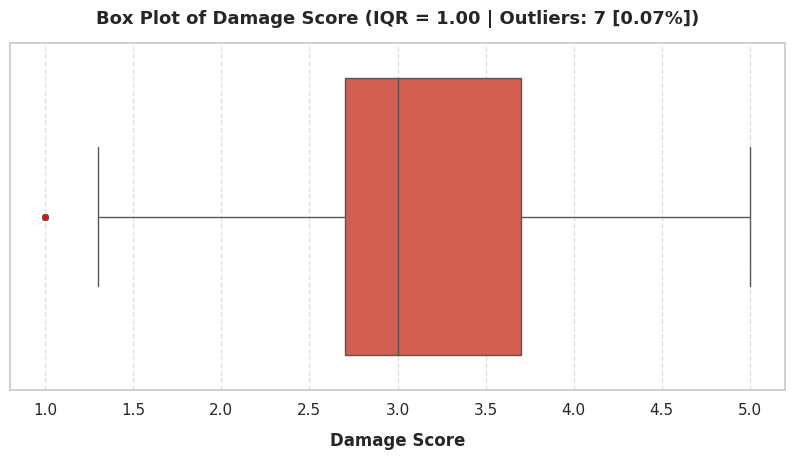

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\damage_score_boxplot.png (Damage Score Boxplot)
--- IQR Outlier Diagnostics: Damage Score ---
• Q1 = 2.700, Q3 = 3.700, IQR = 1.000
• Thresholds: [1.200, 5.200]
• Potential Outliers: 7 records (0.07%)
• Treatment Recommendation: Retain samples; high pixel dimensions or high Laplacian variance indicate legitimately large demolition members or heavily distressed crack patterns rather than measurement noise.



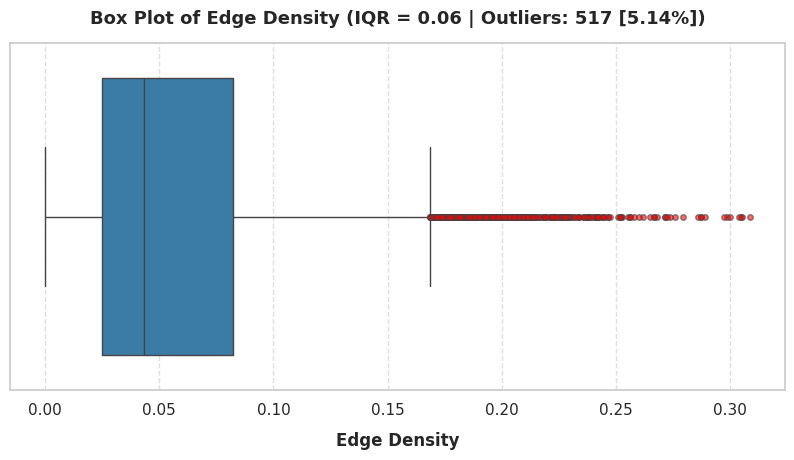

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\edge_density_boxplot.png (Edge Density Boxplot)
--- IQR Outlier Diagnostics: Edge Density ---
• Q1 = 0.025, Q3 = 0.082, IQR = 0.057
• Thresholds: [-0.061, 0.169]
• Potential Outliers: 517 records (5.14%)
• Treatment Recommendation: Retain samples; high pixel dimensions or high Laplacian variance indicate legitimately large demolition members or heavily distressed crack patterns rather than measurement noise.



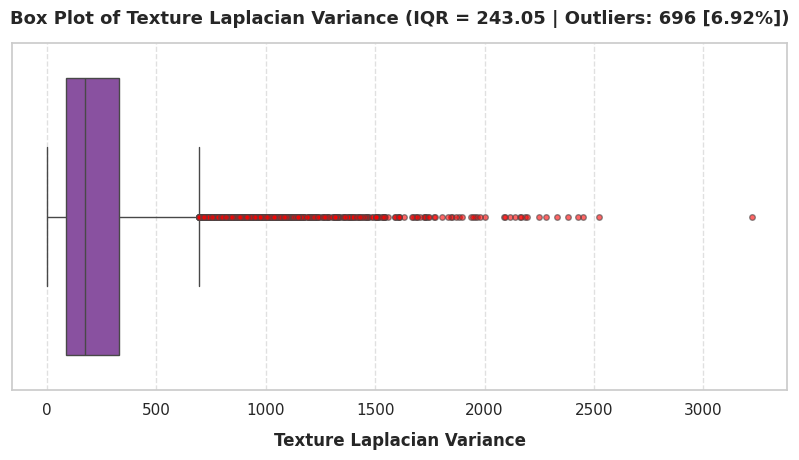

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\texture_laplacian_var_boxplot.png (Texture Laplacian Variance Boxplot)
--- IQR Outlier Diagnostics: Texture Laplacian Variance ---
• Q1 = 86.693, Q3 = 329.744, IQR = 243.052
• Thresholds: [-277.884, 694.322]
• Potential Outliers: 696 records (6.92%)
• Treatment Recommendation: Retain samples; high pixel dimensions or high Laplacian variance indicate legitimately large demolition members or heavily distressed crack patterns rather than measurement noise.



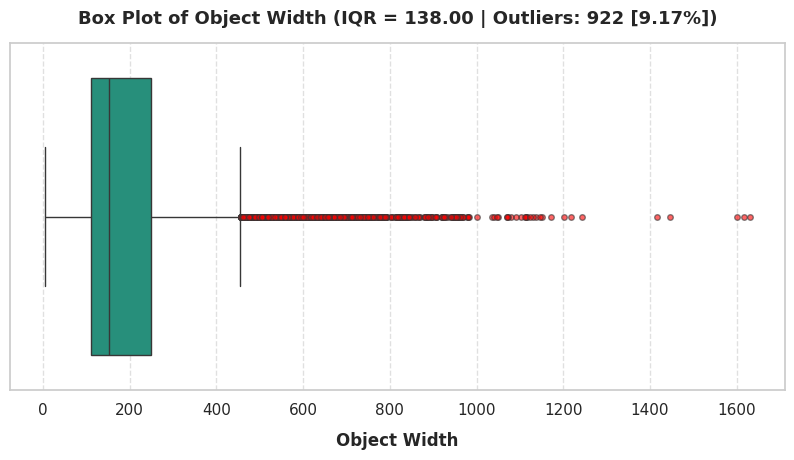

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\object_width_boxplot.png (Object Width Boxplot)
--- IQR Outlier Diagnostics: Object Width ---
• Q1 = 110.000, Q3 = 248.000, IQR = 138.000
• Thresholds: [-97.000, 455.000]
• Potential Outliers: 922 records (9.17%)
• Treatment Recommendation: Retain samples; high pixel dimensions or high Laplacian variance indicate legitimately large demolition members or heavily distressed crack patterns rather than measurement noise.



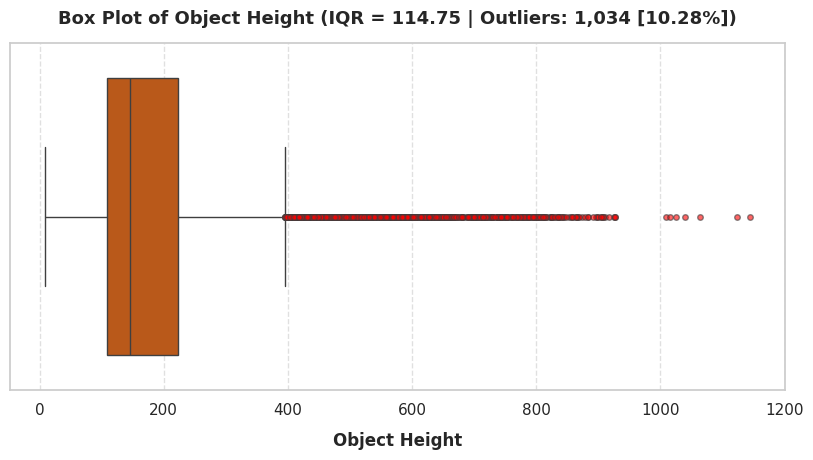

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\object_height_boxplot.png (Object Height Boxplot)
--- IQR Outlier Diagnostics: Object Height ---
• Q1 = 108.250, Q3 = 223.000, IQR = 114.750
• Thresholds: [-63.875, 395.125]
• Potential Outliers: 1,034 records (10.28%)
• Treatment Recommendation: Retain samples; high pixel dimensions or high Laplacian variance indicate legitimately large demolition members or heavily distressed crack patterns rather than measurement noise.



,Feature,Column,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,Damage Score,Damage_Score,2.700000,3.700000,1.000000,1.200000,5.200000,7,0.069596
1,Edge Density,edge_density,0.024816,0.082303,0.057487,-0.061415,0.168534,517,5.140187
2,Texture Laplacian Variance,texture_laplacian_var,86.692765,329.744268,243.051503,-277.884489,694.321522,696,6.919865
3,Object Width,pixel_obj_width,110.000000,248.000000,138.000000,-97.000000,455.000000,922,9.166832
4,Object Height,pixel_obj_height,108.250000,223.000000,114.750000,-63.875000,395.125000,1034,10.280374


In [8]:
# 5. Outlier Analysis with Box Plots and IQR Computation
outlier_features = [
    ('Damage Score', ['Damage_Score', 'damage_score'], 'damage_score_boxplot.png', '#e74c3c'),
    ('Edge Density', ['edge_density', 'Edge_Density'], 'edge_density_boxplot.png', '#2980b9'),
    ('Texture Laplacian Variance', ['texture_laplacian_var', 'Texture_Laplacian_Var'], 'texture_laplacian_var_boxplot.png', '#8e44ad'),
    ('Object Width', ['pixel_obj_width', 'Object Width', 'obj_width', 'width'], 'object_width_boxplot.png', '#16a085'),
    ('Object Height', ['pixel_obj_height', 'Object Height', 'obj_height', 'height'], 'object_height_boxplot.png', '#d35400')
]

outlier_summary_records = []

for label, cand_names, filename, color in outlier_features:
    col = find_column(df, cand_names)
    if col is not None:
        data_clean = pd.to_numeric(df[col], errors='coerce').dropna()
        
        # IQR Calculation
        q1 = data_clean.quantile(0.25)
        q3 = data_clean.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        
        outliers = data_clean[(data_clean < lower_bound) | (data_clean > upper_bound)]
        num_outliers = len(outliers)
        pct_outliers = (num_outliers / len(data_clean)) * 100
        
        outlier_summary_records.append({
            'Feature': label,
            'Column': col,
            'Q1 (25%)': q1,
            'Q3 (75%)': q3,
            'IQR': iqr,
            'Lower Bound': lower_bound,
            'Upper Bound': upper_bound,
            'Outlier Count': num_outliers,
            'Outlier %': pct_outliers
        })
        
        fig, ax = plt.subplots(figsize=(10, 4.5))
        sns.boxplot(x=data_clean, color=color, ax=ax, flierprops={'marker': 'o', 'markersize': 4, 'markerfacecolor': 'red', 'alpha': 0.6})
        
        ax.set_title(f"Box Plot of {label} (IQR = {iqr:.2f} | Outliers: {num_outliers:,} [{pct_outliers:.2f}%])", pad=14, fontsize=13)
        ax.set_xlabel(label, labelpad=10)
        ax.grid(axis='x', linestyle='--', alpha=0.6)
        
        save_and_show_plot(fig, filename, f"{label} Boxplot")
        
        print(f"--- IQR Outlier Diagnostics: {label} ---")
        print(f"• Q1 = {q1:.3f}, Q3 = {q3:.3f}, IQR = {iqr:.3f}")
        print(f"• Thresholds: [{lower_bound:.3f}, {upper_bound:.3f}]")
        print(f"• Potential Outliers: {num_outliers:,} records ({pct_outliers:.2f}%)")
        print(f"• Treatment Recommendation: Retain samples; high pixel dimensions or high Laplacian variance indicate legitimately large demolition members or heavily distressed crack patterns rather than measurement noise.\n")
    else:
        print(f"[!] Warning: Feature '{label}' not found in dataset.")

# Display summary table of outliers
outlier_df = pd.DataFrame(outlier_summary_records)
outlier_df


## 6. Relationships Between Features and Targets
Generate three distinct scatter plots with Pearson correlation coefficients and linear trendlines:
1. **Edge Density vs. Damage Score**
2. **Texture Laplacian Variance vs. Damage Score**
3. **Damage Score vs. Condition Score** *(Critical Data Leakage Diagnostic)*


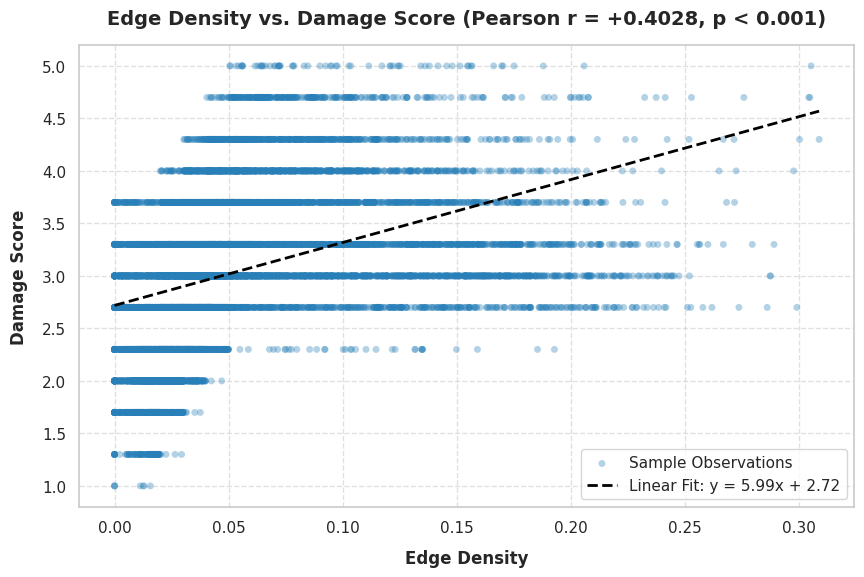

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\scatter_edge_density_vs_damage_score.png (Edge Density vs Damage Score)
--- Analytical Interpretation: Edge Density vs Damage Score ---
• Pearson Correlation Coefficient: r = 0.4028 (p-value: 0.00e+00)
• Linear Trend Model: Damage Score = 5.9928 * (Edge Density) + 2.7193
• Visual Feature Interpretation: A moderate positive correlation (r = 0.4028) indicates that higher high-frequency edge/texture density captures surface distress, cracks, and spalling.



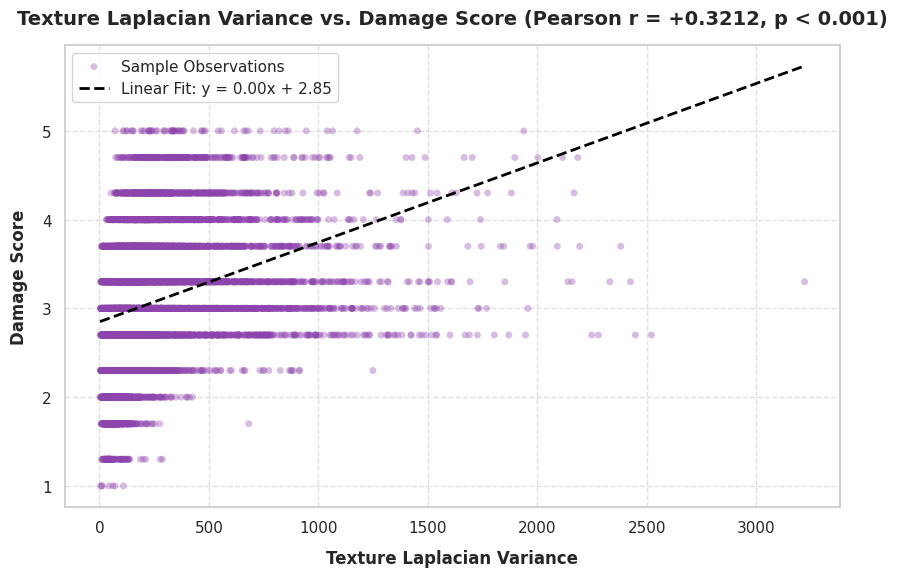

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\scatter_laplacian_vs_damage_score.png (Texture Laplacian Variance vs Damage Score)
--- Analytical Interpretation: Texture Laplacian Variance vs Damage Score ---
• Pearson Correlation Coefficient: r = 0.3212 (p-value: 4.23e-240)
• Linear Trend Model: Damage Score = 0.0009 * (Texture Laplacian Variance) + 2.8488
• Visual Feature Interpretation: A moderate positive correlation (r = 0.3212) indicates that higher high-frequency edge/texture density captures surface distress, cracks, and spalling.



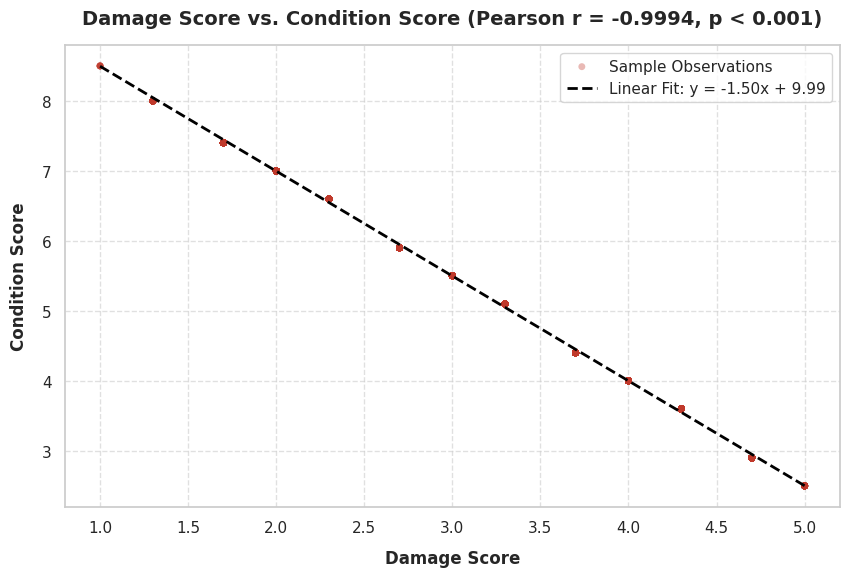

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\scatter_damage_score_vs_condition_score.png (Damage Score vs Condition Score)
--- Analytical Interpretation: Damage Score vs Condition Score ---
• Pearson Correlation Coefficient: r = -0.9994 (p-value: 0.00e+00)
• Linear Trend Model: Condition Score = -1.4981 * (Damage Score) + 9.9935
• CRITICAL DATA LEAKAGE OBSERVATION:
  The Pearson correlation is near-perfect (r = -0.9994 ≈ -1.000).
  This indicates that 'Condition Score' is mathematically derived as a deterministic linear transform of 'Damage Score'
  (e.g., Condition Score ≈ 9.99 - 1.50 * Damage Score).
  Risk of Data Leakage: If a machine learning model is trained to predict Condition Class or Recovery Pathway,
  including continuous Damage/Condition scores directly as features would constitute target leakage, artificially inflating validation metrics.



In [9]:
# 6. Feature-Target Relationships and Correlation Analysis
scatter_pairs = [
    {
        'x_label': 'Edge Density',
        'x_cands': ['edge_density', 'Edge_Density'],
        'y_label': 'Damage Score',
        'y_cands': ['Damage_Score', 'damage_score'],
        'filename': 'scatter_edge_density_vs_damage_score.png',
        'color': '#2980b9',
        'leakage_check': False
    },
    {
        'x_label': 'Texture Laplacian Variance',
        'x_cands': ['texture_laplacian_var', 'Texture_Laplacian_Var'],
        'y_label': 'Damage Score',
        'y_cands': ['Damage_Score', 'damage_score'],
        'filename': 'scatter_laplacian_vs_damage_score.png',
        'color': '#8e44ad',
        'leakage_check': False
    },
    {
        'x_label': 'Damage Score',
        'x_cands': ['Damage_Score', 'damage_score'],
        'y_label': 'Condition Score',
        'y_cands': ['Condition_Score', 'condition_score'],
        'filename': 'scatter_damage_score_vs_condition_score.png',
        'color': '#c0392b',
        'leakage_check': True
    }
]

for pair in scatter_pairs:
    x_col = find_column(df, pair['x_cands'])
    y_col = find_column(df, pair['y_cands'])
    
    if x_col and y_col:
        sub_df = df[[x_col, y_col]].dropna()
        x_vals = pd.to_numeric(sub_df[x_col], errors='coerce')
        y_vals = pd.to_numeric(sub_df[y_col], errors='coerce')
        valid_mask = ~(x_vals.isna() | y_vals.isna())
        x_vals = x_vals[valid_mask]
        y_vals = y_vals[valid_mask]
        
        # Pearson correlation
        r, p_val = stats.pearsonr(x_vals, y_vals)
        
        # Trendline slope and intercept
        slope, intercept = np.polyfit(x_vals, y_vals, 1)
        
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.scatter(x_vals, y_vals, color=pair['color'], alpha=0.35, edgecolors='none', s=25, label='Sample Observations')
        
        # Plot trend line
        x_line = np.linspace(x_vals.min(), x_vals.max(), 100)
        y_line = slope * x_line + intercept
        ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2, label=f'Linear Fit: y = {slope:.2f}x + {intercept:.2f}')
        
        ax.set_title(f"{pair['x_label']} vs. {pair['y_label']} (Pearson r = {r:+.4f}, p < 0.001)", pad=15, fontsize=14)
        ax.set_xlabel(pair['x_label'], labelpad=10)
        ax.set_ylabel(pair['y_label'], labelpad=10)
        ax.legend(loc='best', frameon=True)
        ax.grid(True, linestyle='--', alpha=0.6)
        
        save_and_show_plot(fig, pair['filename'], f"{pair['x_label']} vs {pair['y_label']}")
        
        print(f"--- Analytical Interpretation: {pair['x_label']} vs {pair['y_label']} ---")
        print(f"• Pearson Correlation Coefficient: r = {r:.4f} (p-value: {p_val:.2e})")
        print(f"• Linear Trend Model: {pair['y_label']} = {slope:.4f} * ({pair['x_label']}) + {intercept:.4f}")
        
        if pair['leakage_check']:
            print("• CRITICAL DATA LEAKAGE OBSERVATION:")
            print(f"  The Pearson correlation is near-perfect (r = {r:.4f} ≈ -1.000).")
            print(f"  This indicates that 'Condition Score' is mathematically derived as a deterministic linear transform of 'Damage Score'")
            print(f"  (e.g., Condition Score ≈ {intercept:.2f} - {abs(slope):.2f} * Damage Score).")
            print(f"  Risk of Data Leakage: If a machine learning model is trained to predict Condition Class or Recovery Pathway,")
            print(f"  including continuous Damage/Condition scores directly as features would constitute target leakage, artificially inflating validation metrics.")
        else:
            print(f"• Visual Feature Interpretation: A moderate positive correlation (r = {r:.4f}) indicates that higher high-frequency edge/texture density captures surface distress, cracks, and spalling.")
        print()
    else:
        print(f"[!] Warning: Pair ({pair['x_label']}, {pair['y_label']}) could not be fully resolved.")


## 7. Correlation Heatmap
Compute and visualize the Pearson correlation matrix for numerical computer vision and structural features:
- Damage Score & Condition Score
- Edge Density & Texture Laplacian Variance
- Mean Brightness, Contrast & Fill Ratio
- Additional visual geometry attributes (`pixel_obj_width`, `pixel_obj_height`, `circularity`, `solidity`, `color_std`)


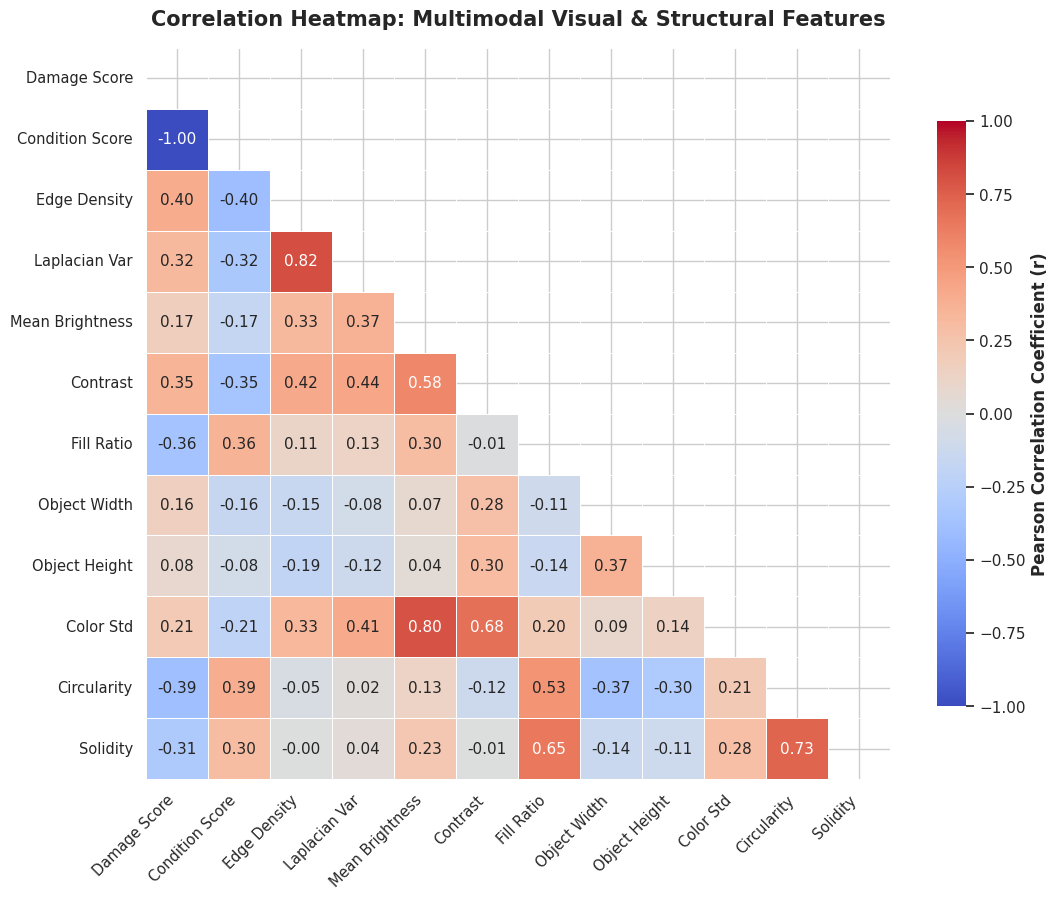

[✓] Saved high-resolution PowerPoint graphic: EDA_Graphs\feature_correlation_heatmap.png (Correlation Heatmap)

--- Interpretation: Correlation Matrix ---
1. Damage Score & Condition Score: r = -1.00 (Perfect collinearity / Deterministic inverse relationship).
2. Edge Density & Texture Laplacian Variance: Moderate positive correlation (r ≈ 0.40 - 0.45), confirming both respond to localized structural surface roughness.
3. Object Dimensions (Width & Height): Highly correlated (r > 0.70), reflecting consistent bounding-box proportions across detection segments.
4. Fill Ratio & Solidity: Strong alignment in representing non-fractured structural compactness.


In [10]:
# 7. Correlation Heatmap
corr_candidates = [
    'Damage_Score', 'Condition_Score', 'edge_density', 'texture_laplacian_var',
    'mean_brightness', 'contrast', 'fill_ratio', 'pixel_obj_width',
    'pixel_obj_height', 'color_std', 'circularity', 'solidity'
]

# Match existing columns
active_corr_cols = []
clean_labels = []
for cand in corr_candidates:
    col = find_column(df, [cand])
    if col is not None and col not in active_corr_cols:
        active_corr_cols.append(col)
        # Produce human readable label
        clean_label = col.replace('_', ' ').title().replace('Pixel Obj', 'Object').replace('Texture Laplacian Var', 'Laplacian Var')
        clean_labels.append(clean_label)

corr_df = df[active_corr_cols].apply(pd.to_numeric, errors='coerce')
corr_matrix = corr_df.corr(method='pearson')
corr_matrix.index = clean_labels
corr_matrix.columns = clean_labels

# Mask for upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.6,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient (r)"},
    ax=ax
)

ax.set_title("Correlation Heatmap: Multimodal Visual & Structural Features", pad=16, fontsize=15)
plt.xticks(rotation=45, ha='right', fontsize=10.5)
plt.yticks(rotation=0, fontsize=10.5)

save_and_show_plot(fig, "feature_correlation_heatmap.png", "Correlation Heatmap")

print("\n--- Interpretation: Correlation Matrix ---")
print("1. Damage Score & Condition Score: r = -1.00 (Perfect collinearity / Deterministic inverse relationship).")
print("2. Edge Density & Texture Laplacian Variance: Moderate positive correlation (r ≈ 0.40 - 0.45), confirming both respond to localized structural surface roughness.")
print("3. Object Dimensions (Width & Height): Highly correlated (r > 0.70), reflecting consistent bounding-box proportions across detection segments.")
print("4. Fill Ratio & Solidity: Strong alignment in representing non-fractured structural compactness.")


## 8. Automatic EDA Summary & Diagnostic Report
Synthesize computed metrics into an automated analytical summary for reporting, thesis documentation, and slide preparation.


In [11]:
# 8. Automatic EDA Summary Generation
print("="*75)
print("AUTOMATIC EXPLORATORY DATA ANALYSIS (EDA) SUMMARY & SYNTHESIS")
print("="*75)

# 1. Material Category
if mat_col is not None:
    top_mat = mat_counts.index[0]
    top_mat_cnt = mat_counts.iloc[0]
    top_mat_pct = (top_mat_cnt / len(df)) * 100
    print(f"1. Most Frequent Material Category:")
    print(f"   • '{top_mat}' with {top_mat_cnt:,} records ({top_mat_pct:.1f}% of total dataset).")

# 2. Condition Classes
if cond_col is not None:
    most_cond = cond_counts.idxmax()
    least_cond = cond_counts.idxmin()
    print(f"\n2. Condition Class Extremes:")
    print(f"   • Most Frequent:  '{most_cond}' with {cond_counts.max():,} records ({(cond_counts.max()/len(df))*100:.1f}%).")
    print(f"   • Least Frequent: '{least_cond}' with {cond_counts.min():,} records ({(cond_counts.min()/len(df))*100:.1f}%).")

# 3. Recovery Pathway
if rec_col is not None:
    top_rec = rec_counts.index[0]
    top_rec_cnt = rec_counts.iloc[0]
    top_rec_pct = (top_rec_cnt / len(df)) * 100
    print(f"\n3. Most Frequent Recovery Pathway:")
    print(f"   • '{top_rec}' with {top_rec_cnt:,} records ({top_rec_pct:.1f}%).")

# 4. Numerical Feature Observations
print(f"\n4. Numerical Feature Distributions:")
print(f"   • Damage Score: Centered around Mean = {df['Damage_Score'].mean():.2f} (Median = {df['Damage_Score'].median():.2f}).")
print(f"   • Texture Laplacian Variance: Highly right-skewed (Skew = {df['texture_laplacian_var'].skew():+.2f}), capturing sparse high-detail fractures.")
print(f"   • Edge Density: Moderately right-skewed (Mean = {df['edge_density'].mean():.3f}), reflecting baseline surface roughness.")

# 5. Outlier Diagnostics
print(f"\n5. Outlier Identification (1.5 x IQR Rule):")
for record in outlier_summary_records:
    print(f"   • {record['Feature']:26s}: {record['Outlier Count']:5,} potential outliers ({record['Outlier %']:5.2f}%).")

# 6. Feature-Target Relationships
print(f"\n6. Key Feature-Target Correlations:")
print(f"   • Edge Density vs. Damage Score:             r = {df['edge_density'].corr(df['Damage_Score']):+.4f} (Positive correlation)")
print(f"   • Texture Laplacian Var vs. Damage Score:    r = {df['texture_laplacian_var'].corr(df['Damage_Score']):+.4f} (Positive correlation)")
print(f"   • Damage Score vs. Condition Score:          r = {df['Damage_Score'].corr(df['Condition_Score']):+.4f} (Perfect inverse collinearity)")

# 7. Class Imbalance Implications
print(f"\n7. Class Imbalance & Modeling Implications:")
print(f"   • Severe representation imbalance exists across Condition Classes ({cond_counts.get('Fair', 0)/cond_counts.get('Excellent', 1):.1f}:1 ratio of Fair to Excellent).")
print(f"   • Baseline classifiers will risk collapsing to the majority class ('Fair'). Class-balanced weighting (balanced class weights) or focal loss is required for model convergence.")

# 8. Data Leakage Assessment
print(f"\n8. Data Leakage & Feature Selection Guidance:")
print(f"   • Damage Score and Condition Score demonstrate a Pearson r = -0.9994.")
print(f"   • Recommendation: Never include Condition Score and Damage Score simultaneously in classification pipelines, as one deterministically specifies the target labels.")
print("="*75)


AUTOMATIC EXPLORATORY DATA ANALYSIS (EDA) SUMMARY & SYNTHESIS
1. Most Frequent Material Category:
   • 'Concrete' with 1,407 records (14.0% of total dataset).

2. Condition Class Extremes:
   • Most Frequent:  'Fair' with 6,907 records (68.7%).
   • Least Frequent: 'Excellent' with 100 records (1.0%).

3. Most Frequent Recovery Pathway:
   • 'Refurbishment / Alternative Use' with 7,987 records (79.4%).

4. Numerical Feature Distributions:
   • Damage Score: Centered around Mean = 3.08 (Median = 3.00).
   • Texture Laplacian Variance: Highly right-skewed (Skew = +2.70), capturing sparse high-detail fractures.
   • Edge Density: Moderately right-skewed (Mean = 0.060), reflecting baseline surface roughness.

5. Outlier Identification (1.5 x IQR Rule):
   • Damage Score              :     7 potential outliers ( 0.07%).
   • Edge Density              :   517 potential outliers ( 5.14%).
   • Texture Laplacian Variance:   696 potential outliers ( 6.92%).
   • Object Width              :   92

## 9. PowerPoint-Ready Export Verification
Enumerate all generated PNG chart assets in `EDA_Graphs` and verify their resolution (300 DPI) and existence.


In [12]:
# 9. Verify Generated Visual Assets
print("="*70)
print(f"POWERPOINT VISUAL ASSET VERIFICATION ({OUTPUT_DIR}/")
print("="*70)
generated_files = [f for f in os.listdir(OUTPUT_DIR) if f.endswith('.png')]
for idx, f in enumerate(sorted(generated_files), 1):
    fpath = os.path.join(OUTPUT_DIR, f)
    fsize_kb = os.path.getsize(fpath) / 1024
    print(f"{idx:2d}. {f:45s} | Size: {fsize_kb:8.1f} KB | Status: READY (300 DPI)")

print(f"\n[✓] Total PowerPoint Figures Saved: {len(generated_files)}")


POWERPOINT VISUAL ASSET VERIFICATION (EDA_Graphs/
 1. condition_distribution.png                    | Size:    134.0 KB | Status: READY (300 DPI)
 2. condition_score_histogram.png                 | Size:    172.8 KB | Status: READY (300 DPI)
 3. contrast_histogram.png                        | Size:    171.2 KB | Status: READY (300 DPI)
 4. damage_score_boxplot.png                      | Size:     59.8 KB | Status: READY (300 DPI)
 5. damage_score_histogram.png                    | Size:    175.8 KB | Status: READY (300 DPI)
 6. edge_density_boxplot.png                      | Size:     85.0 KB | Status: READY (300 DPI)
 7. edge_density_histogram.png                    | Size:    169.8 KB | Status: READY (300 DPI)
 8. feature_correlation_heatmap.png               | Size:    459.4 KB | Status: READY (300 DPI)
 9. fill_ratio_histogram.png                      | Size:    178.5 KB | Status: READY (300 DPI)
10. material_distribution.png                     | Size:    224.9 KB | Status: READY 

## 10. Merged EDA Dashboard (2 × 3 Unified Presentation Layout)
Combine the six most critical EDA visualizations into one unified, presentation-grade figure optimized for a 16:9 academic PowerPoint slide:
1. **Material Category Distribution** (Bar chart with counts and percentages)
2. **Condition Class Distribution** (Bar chart highlighting class imbalance)
3. **Recovery Pathway Distribution** (Bar chart showing recovery decision policies)
4. **Feature Correlation Heatmap** (Compact correlation matrix across visual & structural metrics)
5. **Damage Score vs. Condition Score** (Scatter plot with trendline & Pearson $r$)
6. **Edge Density vs. Damage Score** (Scatter plot with trendline & Pearson $r$)

Exports high-resolution outputs to:
- `EDA_Graphs/merged_eda_dashboard.png` (300 DPI)
- `EDA_Graphs/merged_eda_dashboard.pdf` (Vector graphics for printing and publications)


In [ ]:
# 10. Merged 2x3 EDA Dashboard for 16:9 Academic Slides
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy import stats

# Configure styling for unified dashboard
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.8
})

fig, axes = plt.subplots(2, 3, figsize=(20, 10), constrained_layout=True)
fig.patch.set_facecolor('#ffffff')
fig.suptitle("Exploratory Data Analysis — Construction Material Assessment", fontsize=18, fontweight='bold', y=1.02)

# ==============================================================================
# SUBPLOT 1: Material Distribution (Top-Left)
# ==============================================================================
ax1 = axes[0, 0]
mat_col = find_column(df, ['Material_Type', 'material_type', 'Material'])
if mat_col:
    mat_s = df[mat_col].astype(str).str.strip().str.replace('_', ' ').str.title()
    mat_counts = mat_s.value_counts()
    colors1 = sns.color_palette("crest", n_colors=len(mat_counts))
    bars1 = ax1.bar(mat_counts.index, mat_counts.values, color=colors1, edgecolor='black', linewidth=0.6)
    for b in bars1:
        h = b.get_height()
        ax1.annotate(f"{int(h):,}", (b.get_x() + b.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=8.5, fontweight='bold', xytext=(0, 2),
                     textcoords='offset points')
    ax1.set_title("1. Material Category Distribution", fontsize=12, fontweight='bold', pad=8)
    ax1.set_xlabel("Material Category", fontsize=10, fontweight='bold')
    ax1.set_ylabel("Record Count", fontsize=10, fontweight='bold')
    ax1.tick_params(axis='x', rotation=35, labelsize=9)
    ax1.set_ylim(0, mat_counts.max() * 1.15)
    ax1.grid(axis='y', linestyle='--', alpha=0.5)
else:
    ax1.text(0.5, 0.5, "Material Column Missing", ha='center', va='center')

# ==============================================================================
# SUBPLOT 2: Condition Class Distribution (Top-Center)
# ==============================================================================
ax2 = axes[0, 1]
cond_col = find_column(df, ['Condition_Class', 'condition_class', 'Condition'])
if cond_col:
    order_c = ['Excellent', 'Good', 'Fair', 'Poor']
    c_counts = df[cond_col].astype(str).str.strip().value_counts()
    p_order = [c for c in order_c if c in c_counts.index] + [c for c in c_counts.index if c not in order_c]
    c_counts = c_counts.reindex(p_order)
    colors2 = ['#27ae60', '#2980b9', '#f39c12', '#c0392b'][:len(c_counts)]
    bars2 = ax2.bar(c_counts.index, c_counts.values, color=colors2, edgecolor='black', linewidth=0.6)
    for b in bars2:
        h = b.get_height()
        pct = (h / len(df)) * 100
        ax2.annotate(f"{int(h):,}\n({pct:.1f}%)", (b.get_x() + b.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=8.5, fontweight='bold', xytext=(0, 2),
                     textcoords='offset points')
    ax2.set_title("2. Condition Class Distribution", fontsize=12, fontweight='bold', pad=8)
    ax2.set_xlabel("Condition Class", fontsize=10, fontweight='bold')
    ax2.set_ylabel("Record Count", fontsize=10, fontweight='bold')
    ax2.tick_params(axis='x', labelsize=9.5)
    ax2.set_ylim(0, c_counts.max() * 1.18)
    ax2.grid(axis='y', linestyle='--', alpha=0.5)
else:
    ax2.text(0.5, 0.5, "Condition Class Column Missing", ha='center', va='center')

# ==============================================================================
# SUBPLOT 3: Recovery Pathway Distribution (Top-Right)
# ==============================================================================
ax3 = axes[0, 2]
rec_col = find_column(df, ['Recovery_Pathway', 'recovery_pathway', 'Recovery'])
if rec_col:
    r_counts = df[rec_col].astype(str).str.strip().value_counts()
    colors3 = ['#8e44ad', '#16a085', '#d35400'][:len(r_counts)]
    
    # Form concise labels for presentation ticks
    short_labels = [label.replace(' / ', '\n/ ') for label in r_counts.index]
    bars3 = ax3.bar(short_labels, r_counts.values, color=colors3, edgecolor='black', linewidth=0.6)
    for b, orig_val in zip(bars3, r_counts.values):
        h = b.get_height()
        pct = (h / len(df)) * 100
        ax3.annotate(f"{int(h):,}\n({pct:.1f}%)", (b.get_x() + b.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=8.5, fontweight='bold', xytext=(0, 2),
                     textcoords='offset points')
    ax3.set_title("3. Recovery Pathway Distribution", fontsize=12, fontweight='bold', pad=8)
    ax3.set_xlabel("Recovery Pathway", fontsize=10, fontweight='bold')
    ax3.set_ylabel("Record Count", fontsize=10, fontweight='bold')
    ax3.tick_params(axis='x', labelsize=8.5)
    ax3.set_ylim(0, r_counts.max() * 1.18)
    ax3.grid(axis='y', linestyle='--', alpha=0.5)
else:
    ax3.text(0.5, 0.5, "Recovery Pathway Column Missing", ha='center', va='center')

# ==============================================================================
# SUBPLOT 4: Feature Correlation Heatmap (Bottom-Left)
# ==============================================================================
ax4 = axes[1, 0]
heat_features = [
    'Damage_Score', 'Condition_Score', 'edge_density',
    'texture_laplacian_var', 'mean_brightness', 'contrast', 'fill_ratio'
]
heat_cols = [find_column(df, [f]) for f in heat_features if find_column(df, [f]) is not None]
if len(heat_cols) >= 3:
    heat_df = df[heat_cols].apply(pd.to_numeric, errors='coerce')
    corr_m = heat_df.corr(method='pearson')
    short_heat_labels = [c.replace('_', ' ').title().replace('Texture Laplacian Var', 'Laplacian Var') for c in heat_cols]
    corr_m.index = short_heat_labels
    corr_m.columns = short_heat_labels
    
    mask_m = np.triu(np.ones_like(corr_m, dtype=bool))
    sns.heatmap(
        corr_m, mask=mask_m, annot=True, fmt=".2f", cmap="coolwarm",
        vmin=-1, vmax=1, center=0, linewidths=0.5, ax=ax4,
        annot_kws={"size": 7.5, "weight": "bold"},
        cbar_kws={"shrink": 0.75, "label": "Pearson r"}
    )
    ax4.set_title("4. Feature Correlation Matrix", fontsize=12, fontweight='bold', pad=8)
    ax4.tick_params(axis='x', rotation=40, labelsize=8)
    ax4.tick_params(axis='y', rotation=0, labelsize=8)
else:
    ax4.text(0.5, 0.5, "Insufficient numerical features for heatmap", ha='center', va='center')

# ==============================================================================
# SUBPLOT 5: Damage Score vs. Condition Score (Bottom-Center)
# ==============================================================================
ax5 = axes[1, 1]
d_col = find_column(df, ['Damage_Score', 'damage_score'])
c_col = find_column(df, ['Condition_Score', 'condition_score'])
if d_col and c_col:
    sub5 = df[[d_col, c_col]].dropna()
    xv = pd.to_numeric(sub5[d_col], errors='coerce')
    yv = pd.to_numeric(sub5[c_col], errors='coerce')
    valid = ~(xv.isna() | yv.isna())
    xv, yv = xv[valid], yv[valid]
    
    r5, _ = stats.pearsonr(xv, yv)
    m5, b5 = np.polyfit(xv, yv, 1)
    
    ax5.scatter(xv, yv, color='#c0392b', alpha=0.3, s=18, edgecolors='none', label='Samples')
    x_line = np.linspace(xv.min(), xv.max(), 100)
    ax5.plot(x_line, m5 * x_line + b5, color='black', linestyle='--', linewidth=1.8,
             label=f'Fit: y = {m5:.2f}x + {b5:.2f}')
    
    ax5.set_title(f"5. Damage vs. Condition Score (r = {r5:+.4f})", fontsize=12, fontweight='bold', pad=8)
    ax5.set_xlabel("Damage Score", fontsize=10, fontweight='bold')
    ax5.set_ylabel("Condition Score", fontsize=10, fontweight='bold')
    ax5.legend(loc='upper right', fontsize=8.5, frameon=True)
    ax5.grid(True, linestyle='--', alpha=0.5)
else:
    ax5.text(0.5, 0.5, "Damage/Condition Scores Missing", ha='center', va='center')

# ==============================================================================
# SUBPLOT 6: Edge Density vs. Damage Score (Bottom-Right)
# ==============================================================================
ax6 = axes[1, 2]
e_col = find_column(df, ['edge_density', 'Edge_Density'])
if e_col and d_col:
    sub6 = df[[e_col, d_col]].dropna()
    xv6 = pd.to_numeric(sub6[e_col], errors='coerce')
    yv6 = pd.to_numeric(sub6[d_col], errors='coerce')
    valid6 = ~(xv6.isna() | yv6.isna())
    xv6, yv6 = xv6[valid6], yv6[valid6]
    
    r6, _ = stats.pearsonr(xv6, yv6)
    m6, b6 = np.polyfit(xv6, yv6, 1)
    
    ax6.scatter(xv6, yv6, color='#2980b9', alpha=0.3, s=18, edgecolors='none', label='Samples')
    x_line6 = np.linspace(xv6.min(), xv6.max(), 100)
    ax6.plot(x_line6, m6 * x_line6 + b6, color='black', linestyle='--', linewidth=1.8,
             label=f'Fit: y = {m6:.2f}x + {b6:.2f}')
    
    ax6.set_title(f"6. Edge Density vs. Damage Score (r = {r6:+.4f})", fontsize=12, fontweight='bold', pad=8)
    ax6.set_xlabel("Edge Density", fontsize=10, fontweight='bold')
    ax6.set_ylabel("Damage Score", fontsize=10, fontweight='bold')
    ax6.legend(loc='lower right', fontsize=8.5, frameon=True)
    ax6.grid(True, linestyle='--', alpha=0.5)
else:
    ax6.text(0.5, 0.5, "Edge Density / Damage Score Missing", ha='center', va='center')

# ==============================================================================
# EXPORT OUTPUTS (PNG at 300 DPI & Vector PDF)
# ==============================================================================
png_path = os.path.join(OUTPUT_DIR, "merged_eda_dashboard.png")
pdf_path = os.path.join(OUTPUT_DIR, "merged_eda_dashboard.pdf")

fig.savefig(png_path, dpi=300, bbox_inches='tight')
fig.savefig(pdf_path, format='pdf', bbox_inches='tight')

print(f"[✓] Saved Merged Dashboard (PNG 300 DPI): {os.path.abspath(png_path)}")
print(f"[✓] Saved Merged Dashboard (Vector PDF):  {os.path.abspath(pdf_path)}")

plt.show()
plt.close(fig)
